# 06 - Traffic Visualisations with Matplotlib

This learning notebook completes the exploratory visualisation stage of Part 2. It uses the reviewed **one-row-per-hour** feature table so repeated weather observations do not give some timestamps extra weight.

## Learning goals

1. Choose a chart that matches an analytical question.
2. Use Matplotlib to create clear, labelled and reproducible figures.
3. Save every figure and log its path at `INFO` level.
4. Interpret patterns carefully without claiming causation.

> The four figures in this notebook exceed the course requirement of at least three. They will be promoted into `visualizations.py` only after this notebook is reviewed.

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

LOGGER = logging.getLogger("capstone.learning.visualizations")
LOGGER.handlers.clear()
LOGGER.setLevel(logging.DEBUG)
LOGGER.propagate = False
handler = logging.StreamHandler()
handler.setLevel(logging.DEBUG)
handler.setFormatter(
    logging.Formatter("%(asctime)s | %(levelname)s | %(name)s | %(message)s")
)
LOGGER.addHandler(handler)

plt.style.use("seaborn-v0_8-whitegrid")
LOGGER.info("Visualisation environment ready: Matplotlib %s", plt.matplotlib.__version__)

2026-11-15 00:05:42,287 | INFO | capstone.learning.visualizations | Visualisation environment ready: Matplotlib 3.11.2


In [2]:
FEATURES_RELATIVE_PATH = Path("part2_python/data/processed/traffic_features.csv")

def find_project_root(start: Path, relative_path: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / relative_path).is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not find {relative_path}. Run feature_engineering.py first."
    )

PROJECT_ROOT = find_project_root(Path.cwd(), FEATURES_RELATIVE_PATH)
FEATURES_PATH = PROJECT_ROOT / FEATURES_RELATIVE_PATH
FIGURE_DIR = PROJECT_ROOT / "part2_python/reports/figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

features = pd.read_csv(
    FEATURES_PATH,
    parse_dates=["date_time"],
    keep_default_na=False,
)
if features["date_time"].duplicated().any():
    raise ValueError("Feature table contains duplicate timestamps")
if features.isna().any().any():
    raise ValueError("Feature table contains missing values")

LOGGER.info("Loaded feature table with %d rows and %d columns", *features.shape)
LOGGER.debug(
    "Feature date range: %s to %s",
    features["date_time"].min(),
    features["date_time"].max(),
)
display(features.head(3))

2026-11-15 00:05:42,314 | INFO | capstone.learning.visualizations | Loaded feature table with 40575 rows and 36 columns
2026-11-15 00:05:42,314 | DEBUG | capstone.learning.visualizations | Feature date range: 2012-10-02 09:00:00 to 2018-09-30 23:00:00


,date_time,holiday,temp,rain_1h,snow_1h,clouds_all,traffic_volume,weather_Clear,weather_Clouds,weather_Drizzle,...,day_sin,day_cos,is_precipitation,is_low_visibility,is_severe_weather,temp_zscore,clouds_all_zscore,rain_log1p,snow_log1p,congestion_category
0,2012-10-02 09:00:00,None,288.28,0.0,0.0,40.0,5545,0,1,0,...,0.781831,0.62349,0,0,0,0.526867,-0.108610,0.0,0.0,Severe
1,2012-10-02 10:00:00,None,289.36,0.0,0.0,75.0,4516,0,1,0,...,0.781831,0.62349,0,0,0,0.609333,0.796232,0.0,0.0,High
2,2012-10-02 11:00:00,None,289.58,0.0,0.0,90.0,4767,0,1,0,...,0.781831,0.62349,0,0,0,0.626132,1.184021,0.0,0.0,High


In [3]:
saved_figures = []

def save_figure(fig: plt.Figure, filename: str) -> Path:
    output_path = FIGURE_DIR / filename
    fig.savefig(output_path, dpi=160, bbox_inches="tight", facecolor="white")
    if not output_path.is_file() or output_path.stat().st_size == 0:
        raise OSError(f"Figure was not saved correctly: {output_path}")
    saved_figures.append(output_path)
    LOGGER.info("Saved figure: %s", output_path)
    return output_path

COLORS = {
    "blue": "#1f77b4",
    "orange": "#ff7f0e",
    "green": "#2ca02c",
    "red": "#d62728",
}

## Figure 1 - When does traffic demand peak?

A line chart is appropriate because hour is ordered and we want to compare the *shape* of two daily profiles. We calculate the mean from hourly rows and separate weekdays from weekends.

2026-11-15 00:05:42,421 | INFO | capstone.learning.visualizations | Saved figure: /Users/husa/software/AI/nus course/Capstone Project/part2_python/reports/figures/01_hourly_weekday_weekend.png


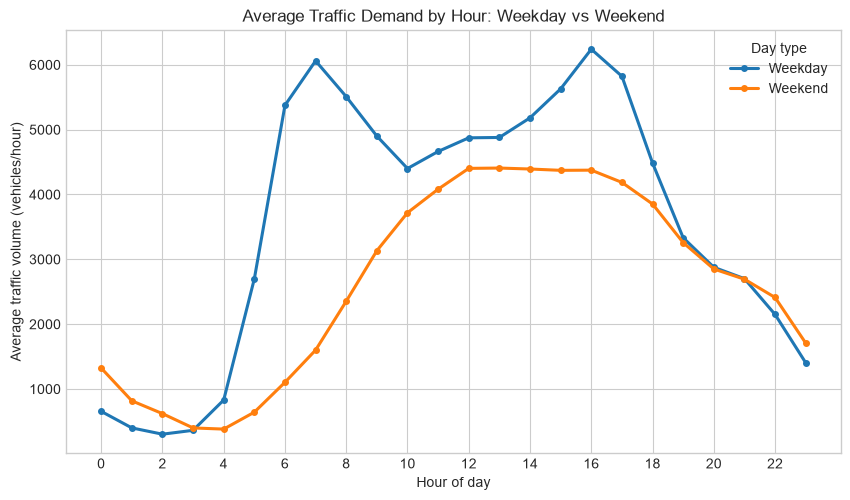

,hour,day_type,traffic_volume
32,16,Weekday,6240.881967
27,13,Weekend,4407.611452


In [4]:
hourly_profile = (
    features.assign(day_type=np.where(features["is_weekend"].eq(1), "Weekend", "Weekday"))
    .groupby(["hour", "day_type"], as_index=False)["traffic_volume"]
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 5.5))
for day_type, color in [("Weekday", COLORS["blue"]), ("Weekend", COLORS["orange"])]:
    subset = hourly_profile.loc[hourly_profile["day_type"].eq(day_type)]
    ax.plot(
        subset["hour"], subset["traffic_volume"],
        marker="o", linewidth=2.2, markersize=4, label=day_type, color=color,
    )
ax.set(
    title="Average Traffic Demand by Hour: Weekday vs Weekend",
    xlabel="Hour of day",
    ylabel="Average traffic volume (vehicles/hour)",
)
ax.set_xticks(range(0, 24, 2))
ax.legend(title="Day type")
save_figure(fig, "01_hourly_weekday_weekend.png")
plt.show()
plt.close(fig)

peak_by_type = (
    hourly_profile.loc[hourly_profile.groupby("day_type")["traffic_volume"].idxmax()]
    .sort_values("day_type")
)
display(peak_by_type)

**Interpretation:** Weekday demand has strong commuter peaks: the highest average is about **6,241 vehicles/hour at 16:00**, with another major peak around 07:00. Weekend demand is flatter and peaks near **13:00 at about 4,408 vehicles/hour**. Traffic-management interventions should therefore distinguish weekday commute periods from weekend midday travel.

## Figure 2 - How is hourly traffic distributed?

A histogram shows the frequency and shape of the continuous traffic-volume distribution. Quartile lines connect this view to the congestion categories created during feature engineering.

2026-11-15 00:05:42,475 | DEBUG | capstone.learning.visualizations | Traffic quartiles used in histogram: {0.25: 1248.5, 0.5: 3427.0, 0.75: 4952.0}
2026-11-15 00:05:42,545 | INFO | capstone.learning.visualizations | Saved figure: /Users/husa/software/AI/nus course/Capstone Project/part2_python/reports/figures/02_traffic_distribution.png


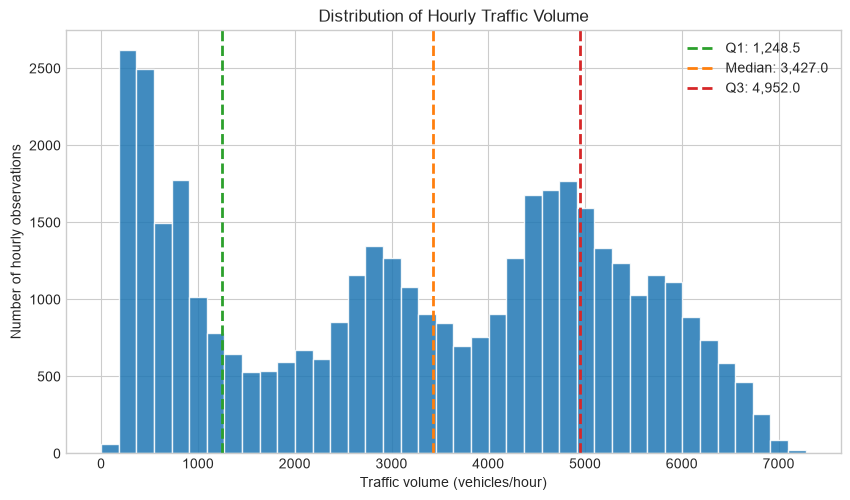

,traffic_volume
mean,3290.650474
median,3427.000000
minimum,0.000000
maximum,7280.000000


In [5]:
traffic_quartiles = features["traffic_volume"].quantile([0.25, 0.50, 0.75])
traffic_mean = float(features["traffic_volume"].mean())
LOGGER.debug("Traffic quartiles used in histogram: %s", traffic_quartiles.to_dict())

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(
    features["traffic_volume"], bins=40,
    color=COLORS["blue"], edgecolor="white", alpha=0.85,
)
for quantile, label, color in [
    (0.25, "Q1", COLORS["green"]),
    (0.50, "Median", COLORS["orange"]),
    (0.75, "Q3", COLORS["red"]),
]:
    value = traffic_quartiles.loc[quantile]
    ax.axvline(value, color=color, linestyle="--", linewidth=2, label=f"{label}: {value:,.1f}")
ax.set(
    title="Distribution of Hourly Traffic Volume",
    xlabel="Traffic volume (vehicles/hour)",
    ylabel="Number of hourly observations",
)
ax.legend()
save_figure(fig, "02_traffic_distribution.png")
plt.show()
plt.close(fig)

display(pd.Series({"mean": traffic_mean, "median": traffic_quartiles.loc[0.50], "minimum": features["traffic_volume"].min(), "maximum": features["traffic_volume"].max()}, name="traffic_volume").to_frame())

**Interpretation:** Hourly traffic spans from **0 to 7,280 vehicles**, with a mean of approximately **3,291** and median of **3,427**. The broad, non-normal shape reflects the mixture of overnight low-demand periods and daytime/commuter demand. The four congestion categories are quartile-based analytical labels, so their near-balanced counts are produced by design rather than being natural operational thresholds.

## Figure 3 - Is temperature strongly related to traffic?

A hexbin plot is clearer than plotting 40,575 overlapping points. Darker cells contain more hourly observations. The correlation is included as a descriptive measure, not evidence that temperature causes traffic changes.

2026-11-15 00:05:42,603 | DEBUG | capstone.learning.visualizations | Temperature and traffic Pearson correlation: 0.139557
2026-11-15 00:05:42,816 | INFO | capstone.learning.visualizations | Saved figure: /Users/husa/software/AI/nus course/Capstone Project/part2_python/reports/figures/03_temperature_traffic_hexbin.png


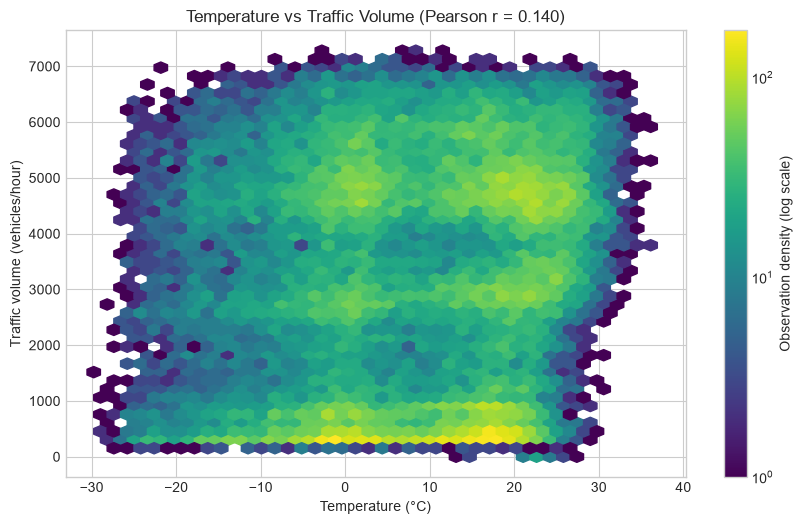

In [6]:
temperature_celsius = features["temp"] - 273.15
temperature_correlation = float(temperature_celsius.corr(features["traffic_volume"]))
LOGGER.debug("Temperature and traffic Pearson correlation: %.6f", temperature_correlation)

fig, ax = plt.subplots(figsize=(10, 5.8))
hexbin = ax.hexbin(
    temperature_celsius, features["traffic_volume"],
    gridsize=42, mincnt=1, cmap="viridis", bins="log",
)
colorbar = fig.colorbar(hexbin, ax=ax)
colorbar.set_label("Observation density (log scale)")
ax.set(
    title=f"Temperature vs Traffic Volume (Pearson r = {temperature_correlation:.3f})",
    xlabel="Temperature (°C)",
    ylabel="Traffic volume (vehicles/hour)",
)
save_figure(fig, "03_temperature_traffic_hexbin.png")
plt.show()
plt.close(fig)

**Interpretation:** The Pearson correlation is only **0.140**, indicating a weak positive linear relationship. High traffic occurs across a broad temperature range, while time-of-day and day type are likely more useful predictors. Seasonal coverage and commuting schedules may confound this relationship, so the chart does not support a causal temperature claim.

## Figure 4 - How does average traffic vary by weather condition?

The hourly table uses multi-hot weather flags because the source sometimes records more than one weather condition for the same timestamp. An hour may therefore contribute to more than one bar. Sample sizes are shown because rare categories can produce unstable averages.

2026-11-15 00:05:42,894 | DEBUG | capstone.learning.visualizations | Weather summary: [{'condition': 'Squall', 'average_traffic': 2061.75, 'hourly_observations': 4}, {'condition': 'Fog', 'average_traffic': 2703.720394736842, 'hourly_observations': 912}, {'condition': 'Mist', 'average_traffic': 2933.0819865319863, 'hourly_observations': 5940}, {'condition': 'Snow', 'average_traffic': 3009.327012522361, 'hourly_observations': 2795}, {'condition': 'Thunderstorm', 'average_traffic': 3009.9168316831683, 'hourly_observations': 1010}, {'condition': 'Clear', 'average_traffic': 3055.7351731358913, 'hourly_observations': 13371}, {'condition': 'Smoke', 'average_traffic': 3237.65, 'hourly_observations': 20}, {'condition': 'Drizzle', 'average_traffic': 3286.561941964286, 'hourly_observations': 1792}, {'condition': 'Rain', 'average_traffic': 3322.444184792378, 'hourly_observations': 5563}, {'condition': 'Haze', 'average_traffic': 3501.2855040470936, 'hourly_observations': 1359}, {'condition': 'Cloud

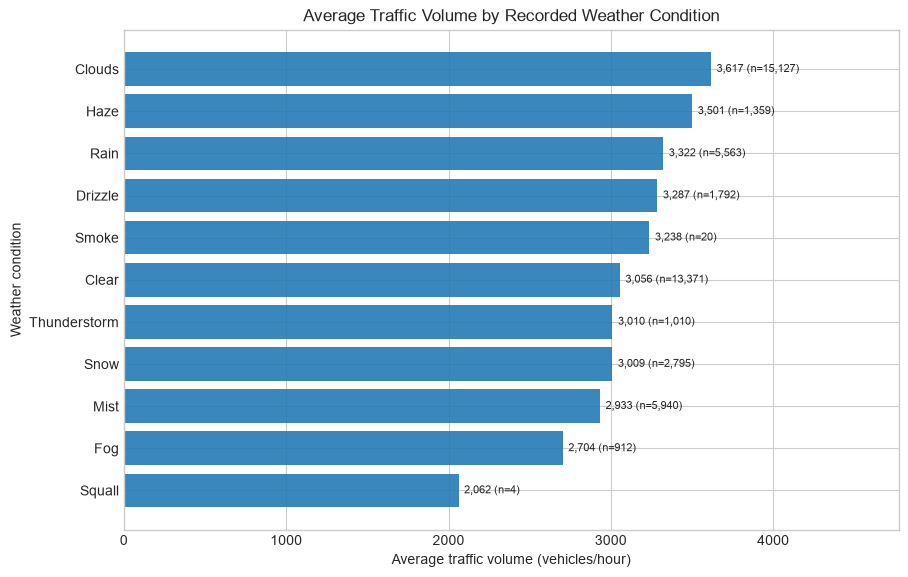

,condition,average_traffic,hourly_observations
0,Clouds,3616.947709,15127
1,Haze,3501.285504,1359
2,Rain,3322.444185,5563
3,Drizzle,3286.561942,1792
4,Smoke,3237.650000,20
5,Clear,3055.735173,13371
6,Thunderstorm,3009.916832,1010
7,Snow,3009.327013,2795
8,Mist,2933.081987,5940
9,Fog,2703.720395,912


In [7]:
weather_columns = sorted(column for column in features.columns if column.startswith("weather_"))
weather_summary = pd.DataFrame(
    {
        "condition": [column.removeprefix("weather_") for column in weather_columns],
        "average_traffic": [
            features.loc[features[column].eq(1), "traffic_volume"].mean()
            for column in weather_columns
        ],
        "hourly_observations": [int(features[column].sum()) for column in weather_columns],
    }
).sort_values("average_traffic", ascending=True)
LOGGER.debug("Weather summary: %s", weather_summary.to_dict(orient="records"))

fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(
    weather_summary["condition"], weather_summary["average_traffic"],
    color=COLORS["blue"], alpha=0.88,
)
ax.bar_label(
    bars,
    labels=[f"{mean:,.0f} (n={count:,})" for mean, count in zip(weather_summary["average_traffic"], weather_summary["hourly_observations"])],
    padding=4, fontsize=8,
)
ax.set(
    title="Average Traffic Volume by Recorded Weather Condition",
    xlabel="Average traffic volume (vehicles/hour)",
    ylabel="Weather condition",
)
ax.set_xlim(0, weather_summary["average_traffic"].max() * 1.32)
save_figure(fig, "04_weather_average_traffic.png")
plt.show()
plt.close(fig)
display(weather_summary.sort_values("average_traffic", ascending=False).reset_index(drop=True))

**Interpretation:** Hours labelled **Clouds** have the highest average traffic at about **3,617 vehicles/hour**. **Squall** is lowest at about **2,062**, but it has only **4 hourly observations**, so that estimate is not reliable for policy. Weather groups occur at different times and seasons; the differences are descriptive associations and should be evaluated alongside calendar features before making decisions.

## Validation gate

The final cell confirms that all four required files exist and that the key reviewed values have not drifted.

In [8]:
expected_filenames = {
    "01_hourly_weekday_weekend.png",
    "02_traffic_distribution.png",
    "03_temperature_traffic_hexbin.png",
    "04_weather_average_traffic.png",
}
assert features.shape == (40_575, 36)
assert len(saved_figures) == 4
assert {path.name for path in saved_figures} == expected_filenames
assert all(path.is_file() and path.stat().st_size > 10_000 for path in saved_figures)
assert np.isclose(temperature_correlation, 0.13955701991709782)
assert int(peak_by_type.loc[peak_by_type["day_type"].eq("Weekday"), "hour"].iloc[0]) == 16
assert int(peak_by_type.loc[peak_by_type["day_type"].eq("Weekend"), "hour"].iloc[0]) == 13
assert weather_summary.iloc[-1]["condition"] == "Clouds"

display(pd.DataFrame({"figure": [path.name for path in saved_figures], "size_kb": [round(path.stat().st_size / 1024, 1) for path in saved_figures]}))
print("PASS - Four Matplotlib visualisations were created, saved and interpreted.")

,figure,size_kb
0,01_hourly_weekday_weekend.png,95.9
1,02_traffic_distribution.png,51.8
2,03_temperature_traffic_hexbin.png,251.0
3,04_weather_average_traffic.png,70.7


PASS - Four Matplotlib visualisations were created, saved and interpreted.
